# Exploratory look at the 2026 daily dataset

Reads `outputs/daily_dataset_2026.csv` (from `scripts/build_daily_dataset_2026.py`).
Uses the **pooled** columns (`*_all`: all NISAR tracks / all S1 orbits together).

1. Time series of every pooled column, one line per field.
2. One summary figure: water level, and HH / HV / VV / VH / NDVI / NDWI against it.

**To use:** edit cell 2, then *Run All*. Figures are saved to `outputs/eda_2026/`.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "legend.title_fontsize": 13, "figure.titlesize": 20,
    "axes.spines.top": False, "axes.spines.right": False,     # clean, open axes
})

# Repo root: works whether Jupyter starts in notebooks/ or in the repo root.
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "scripts").is_dir())

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


## 2. Config — edit here

In [2]:
DATA_CSV = ROOT / "outputs" / "daily_dataset_2026.csv"
OUT_DIR  = ROOT / "outputs" / "eda_2026"

# One colour per field (same order as the gauges file).
FIELD_COLORS = {"Way 3": "#1f77b4", "Way 4": "#17becf", "4 East": "#ff7f0e",
                "South 0": "#2ca02c", "S16": "#d62728"}

# ---- part 1: which columns get a time-series panel --------------------------
# All pooled / single-series columns except bookkeeping. Add or remove freely.
TS_COLUMNS = (
    ["nisar_hh_db_all", "nisar_hv_db_all", "nisar_ratio_db_all", "nisar_inc_deg_all"]
    + ["s1_vv_db_all", "s1_vh_db_all", "s1_ratio_db_all", "s1_ratio_lin_all",
       "s1_waterlike_all", "s1_inc_deg_all"]
    + ["s2_B2", "s2_B3", "s2_B4", "s2_B5", "s2_B6", "s2_B7", "s2_B8", "s2_B8A",
       "s2_B11", "s2_B12", "s2_ndvi", "s2_ndwi",
       "s2_solar_zenith", "s2_solar_azimuth", "s2_view_zenith_B4", "s2_view_azimuth_B4",
       "s2_view_zenith_B8", "s2_view_azimuth_B8"]
    + ["water_mean", "water_min", "water_max", "water_std"]
)
TS_NCOLS = 3            # panels per row

# ---- part 2: the summary figure ---------------------------------------------
# (column, panel title, x-axis label) for panels B onward; water level is panel A.
SUMMARY_VARS = [
    ("nisar_hh_db_all", "NISAR HH",     "HH backscatter [dB]"),
    ("nisar_hv_db_all", "NISAR HV",     "HV backscatter [dB]"),
    ("s1_vv_db_all",    "Sentinel-1 VV", "VV backscatter [dB]"),
    ("s1_vh_db_all",    "Sentinel-1 VH", "VH backscatter [dB]"),
    ("s2_ndvi",         "NDVI",         "NDVI"),
    ("s2_ndwi",         "NDWI",         "NDWI"),
]
# True: correlate only on days the sensor actually observed (gap_days == 0).
# False: all labelled days, interpolated values included (more points, but they
# are not independent -- n then overstates the information).
OBS_DAYS_ONLY = False

# ---- part 3: one figure per field -------------------------------------------
# A = water level; B = one time-series strip per SUMMARY_VARS entry, same dates.
# Colour per variable (marker = shape of the observed-day dots).
VAR_STYLE = {
    "nisar_hh_db_all": ("#1f77b4", "o"), "nisar_hv_db_all": ("#9467bd", "s"),
    "s1_vv_db_all":    ("#ff7f0e", "^"), "s1_vh_db_all":    ("#8c564b", "v"),
    "s2_ndvi":         ("#2ca02c", "D"), "s2_ndwi":         ("#17becf", "P"),
}

# ---- cross-correlation -------------------------------------------------------
# r(k) = Pearson correlation between the variable on day t and water level on
# day t + k, over all days where both exist. k > 0: the variable LEADS water
# level by k days; k < 0: it lags behind. k = 0 is the ordinary same-day r.
MAX_LAG_DAYS   = 15      # search window for the peak, +/- days
SHOW_CCF_PANEL = True    # panel C in the per-field figures: r(k) curves

## 3. Load

In [3]:
d = pd.read_csv(DATA_CSV, parse_dates=["date"])
fields = [f for f in FIELD_COLORS if f in set(d.field)]
OUT_DIR.mkdir(parents=True, exist_ok=True)

# The gap column that tells whether a value was observed (0) or interpolated (> 0).
def gap_col(col):
    for prefix, gap in (("nisar_", "nisar_gap_days_all"), ("s1_", "s1_gap_days_all"),
                        ("s2_", "s2_gap_days")):
        if col.startswith(prefix):
            return gap
    return None                                        # water: never interpolated

def ccf(x, w, max_lag):
    """Cross-correlation r(k) for k = -max_lag..max_lag between two daily series
    (same index, NaN = missing). r(k) = corr(x[t], w[t+k]) over pairs present."""
    x = pd.Series(np.asarray(x, float)); w = pd.Series(np.asarray(w, float))
    lags = np.arange(-max_lag, max_lag + 1)
    r, n = [], []
    for k in lags:
        pair = pd.concat([x, w.shift(-k)], axis=1).dropna()
        n.append(len(pair))
        r.append(pair.iloc[:, 0].corr(pair.iloc[:, 1]) if len(pair) > 2 else np.nan)
    return lags, np.array(r), np.array(n)


def ccf_summary(x, w, max_lag):
    """r at lag 0, and the peak |r| within the window: (r0, n0, r_peak, lag_peak)."""
    lags, r, n = ccf(x, w, max_lag)
    i0 = max_lag
    if np.all(np.isnan(r)):
        return np.nan, 0, np.nan, np.nan
    ip = int(np.nanargmax(np.abs(r)))
    return r[i0], int(n[i0]), r[ip], int(lags[ip])


print(f"{len(d):,} rows, {d.field.nunique()} fields, {d.date.min():%Y-%m-%d} to {d.date.max():%Y-%m-%d}")
print(f"labelled days: {d.water_mean.notna().sum()}")

1,100 rows, 5 fields, 2026-03-15 to 2026-10-20
labelled days: 609


## 4. Time series of every pooled column

Line = daily (interpolated) values; dots = days the sensor actually observed.

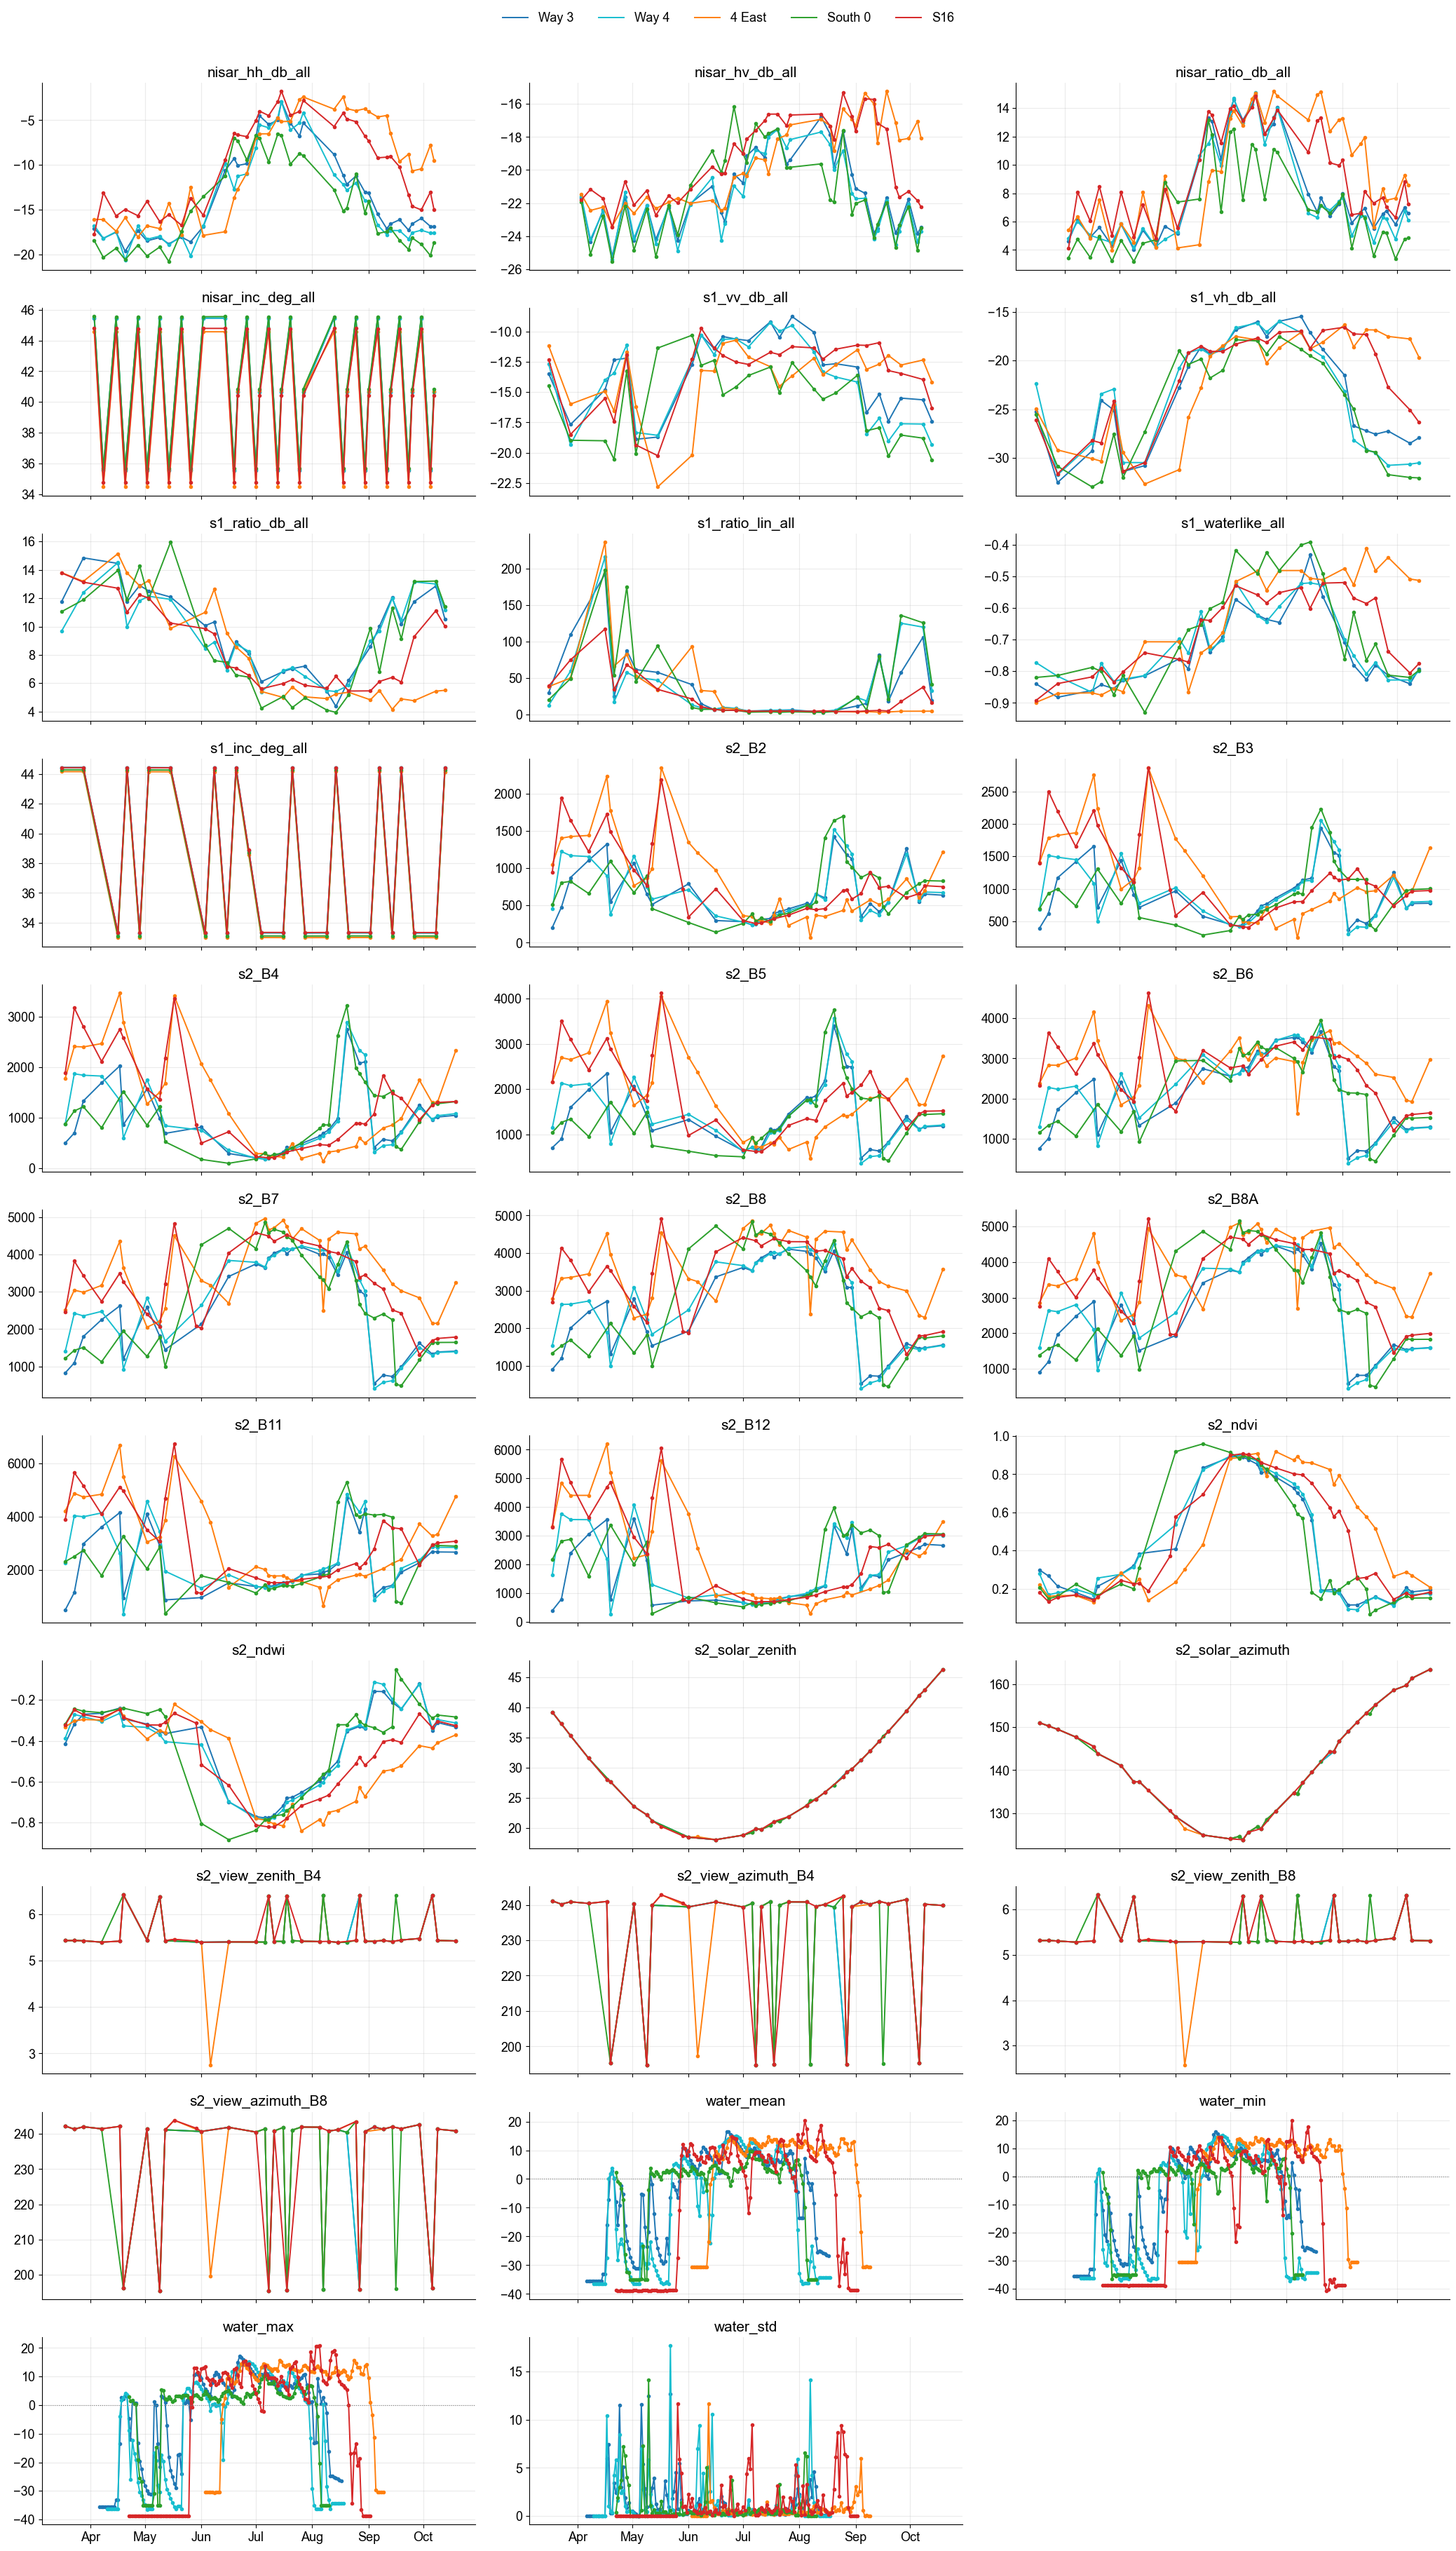

In [4]:
n = len(TS_COLUMNS)
nrows = int(np.ceil(n / TS_NCOLS))
fig, axes = plt.subplots(nrows, TS_NCOLS, figsize=(7 * TS_NCOLS, 3.3 * nrows), sharex=True)
axes = axes.ravel()

for ax, col in zip(axes, TS_COLUMNS):
    gc = gap_col(col)
    for f in fields:
        g = d[d.field == f]
        ax.plot(g.date, g[col], lw=1.4, color=FIELD_COLORS[f], label=f)
        obs = g[g[gc] == 0] if gc else g                # observed days only
        ax.plot(obs.date, obs[col], "o", ms=3, color=FIELD_COLORS[f])
    if col.startswith("water_mean") or col.startswith("water_m"):
        ax.axhline(0, color="grey", lw=0.8, ls=":")     # 0 cm = soil surface
    ax.set_title(col, fontsize=15)
    ax.grid(alpha=0.25)
for ax in axes[n:]:                                     # hide unused panels
    ax.set_visible(False)
for ax in axes[max(0, n - TS_NCOLS):n]:
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(fields), frameon=False,
           bbox_to_anchor=(0.5, 1.005))
fig.tight_layout(rect=[0, 0, 1, 0.985])
fig.savefig(OUT_DIR / "timeseries_all_columns.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Summary figure

A: water level through the season. B–G: each variable against water level,
one colour per field; dotted line = 0 cm (soil surface). Subtitle: lag-0 cross-correlation
(same-day Pearson r) over all fields, and the number of days used.

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


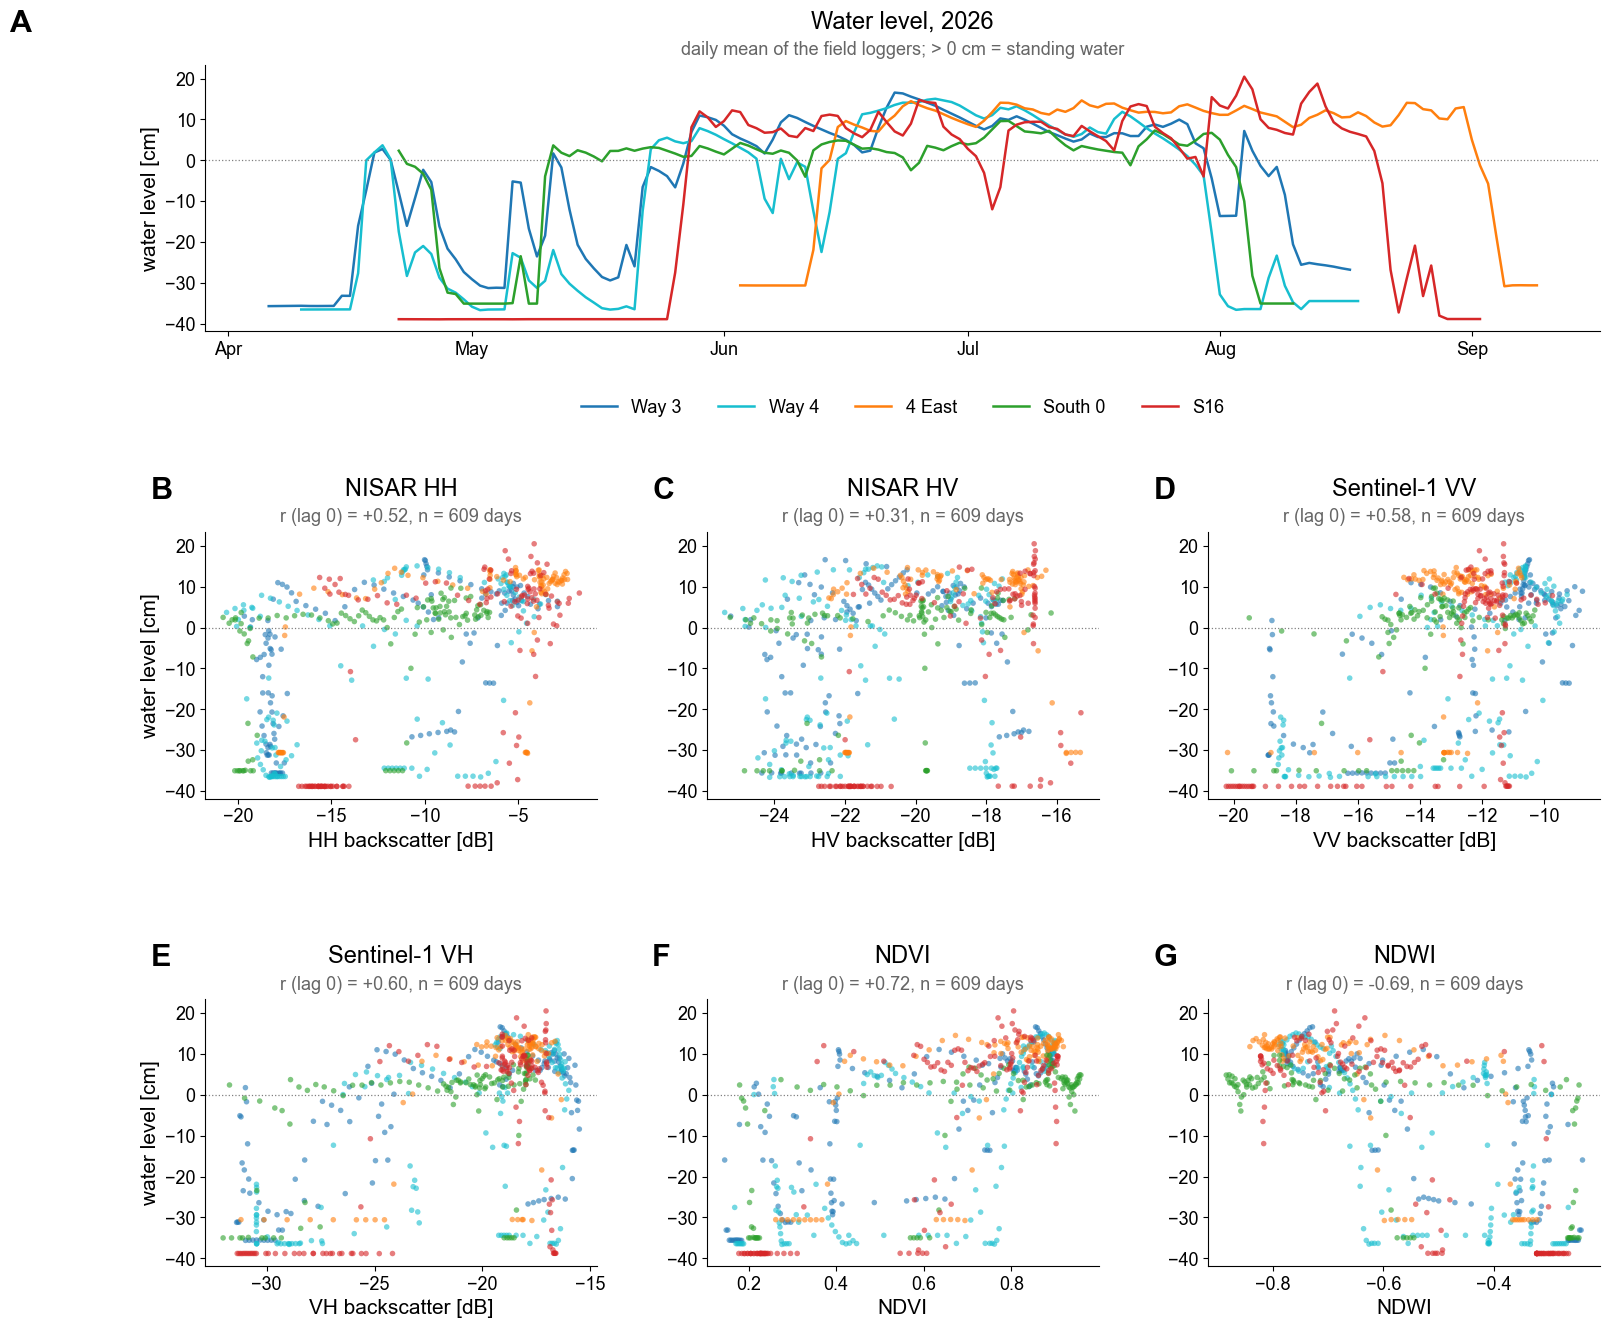

In [5]:
def panel_letter(ax, letter):
    ax.text(-0.14, 1.10, letter, transform=ax.transAxes, fontsize=22, fontweight="bold", va="bottom")


def subtitle(ax, text):
    ax.text(0.5, 1.02, text, transform=ax.transAxes, ha="center", va="bottom",
            fontsize=13, color="#666666")


nvar = len(SUMMARY_VARS)
ncols = 3
nrows = 1 + int(np.ceil(nvar / ncols))
fig = plt.figure(figsize=(18, 5.2 * nrows))
gs = fig.add_gridspec(nrows, ncols, hspace=0.75, wspace=0.28)

# ---- A: water level time series (spans the top row) -------------------------
ax = fig.add_subplot(gs[0, :])
for f in fields:
    g = d[d.field == f]
    ax.plot(g.date, g.water_mean, lw=1.8, color=FIELD_COLORS[f], label=f)
ax.axhline(0, color="grey", lw=0.9, ls=":")
ax.set_ylabel("water level [cm]")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(ncol=len(fields), frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.38))
ax.set_title("Water level, 2026", pad=26)
subtitle(ax, "daily mean of the field loggers; > 0 cm = standing water")
panel_letter(ax, "A")

# ---- B onward: each variable vs water level ---------------------------------
letters = "BCDEFGHIJKLMNOP"
for i, (col, title, xlabel) in enumerate(SUMMARY_VARS):
    ax = fig.add_subplot(gs[1 + i // ncols, i % ncols])
    sub = d.dropna(subset=[col, "water_mean"])
    gc = gap_col(col)
    if OBS_DAYS_ONLY and gc:
        sub = sub[sub[gc] == 0]
    for f in fields:
        g = sub[sub.field == f]
        ax.scatter(g[col], g.water_mean, s=16, alpha=0.6, color=FIELD_COLORS[f],
                   edgecolor="none")
    ax.axhline(0, color="grey", lw=0.9, ls=":")
    # Lag-0 cross-correlation coefficient = same-day Pearson r, pooled over fields.
    r0 = sub[col].corr(sub.water_mean) if len(sub) > 2 else np.nan
    ax.set_title(title, pad=26)
    subtitle(ax, f"r (lag 0) = {r0:+.2f}, n = {len(sub)} days")
    ax.set_xlabel(xlabel)
    if i % ncols == 0:
        ax.set_ylabel("water level [cm]")
    panel_letter(ax, letters[i])

fig.savefig(OUT_DIR / "summary_figure.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the n:** with `OBS_DAYS_ONLY = False` most points are interpolated
days, which are not independent of their neighbours. Set it to `True` to keep
only real acquisition days.

## 6. One figure per field

A: the field's water level. B: each variable as its own time series on the same
dates (line = daily, dots = real acquisitions). Right-hand note: cross-correlation
with water level -- r at lag 0, and the peak r within ±`MAX_LAG_DAYS` with its lag
(positive lag = the variable leads water level). C: the full r(lag) curves.

Cross-correlation uses only days inside the field's water-level window (first to last logger day, shaded grey in B), for both series, so lagged pairs never use satellite days outside it. The number of pairs therefore shrinks as |lag| grows.

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


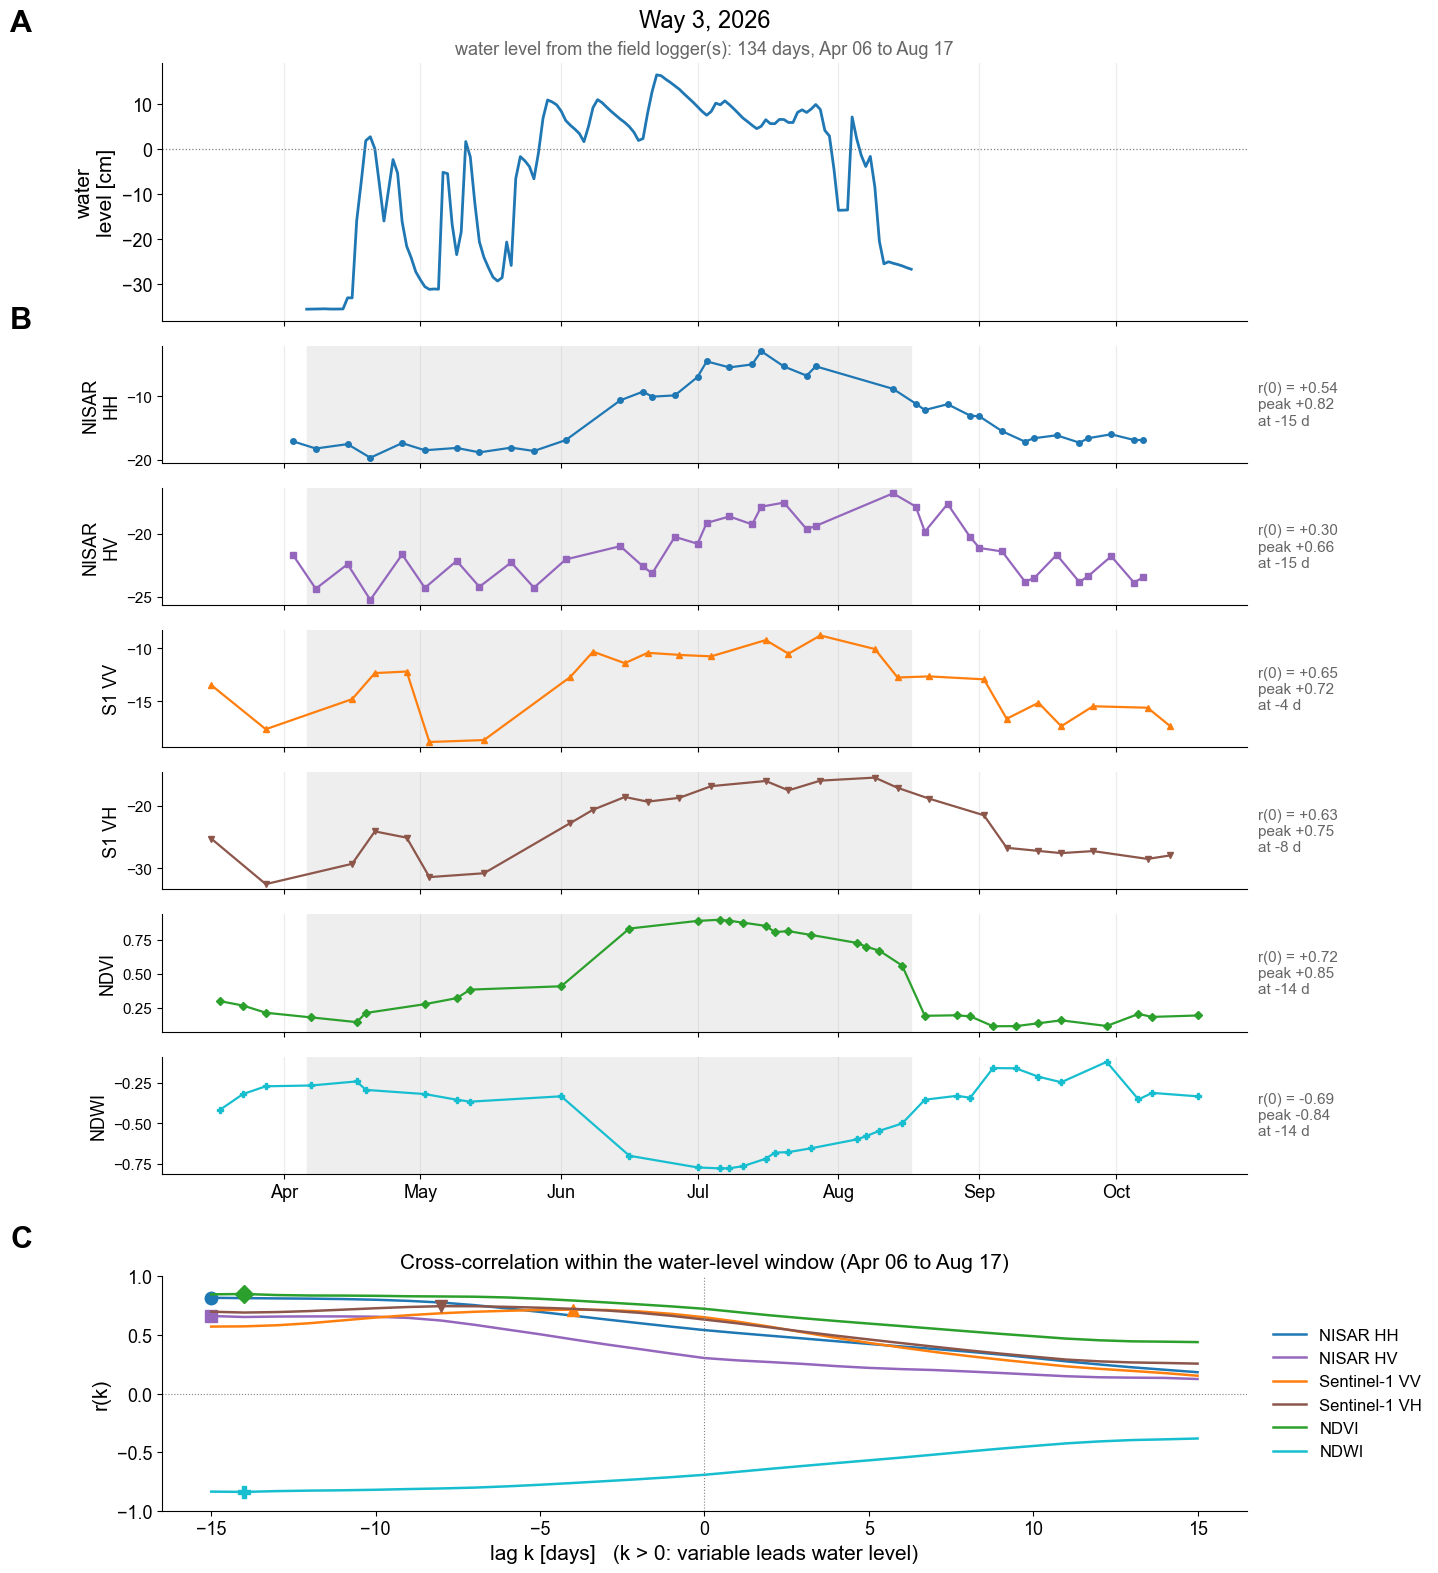

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


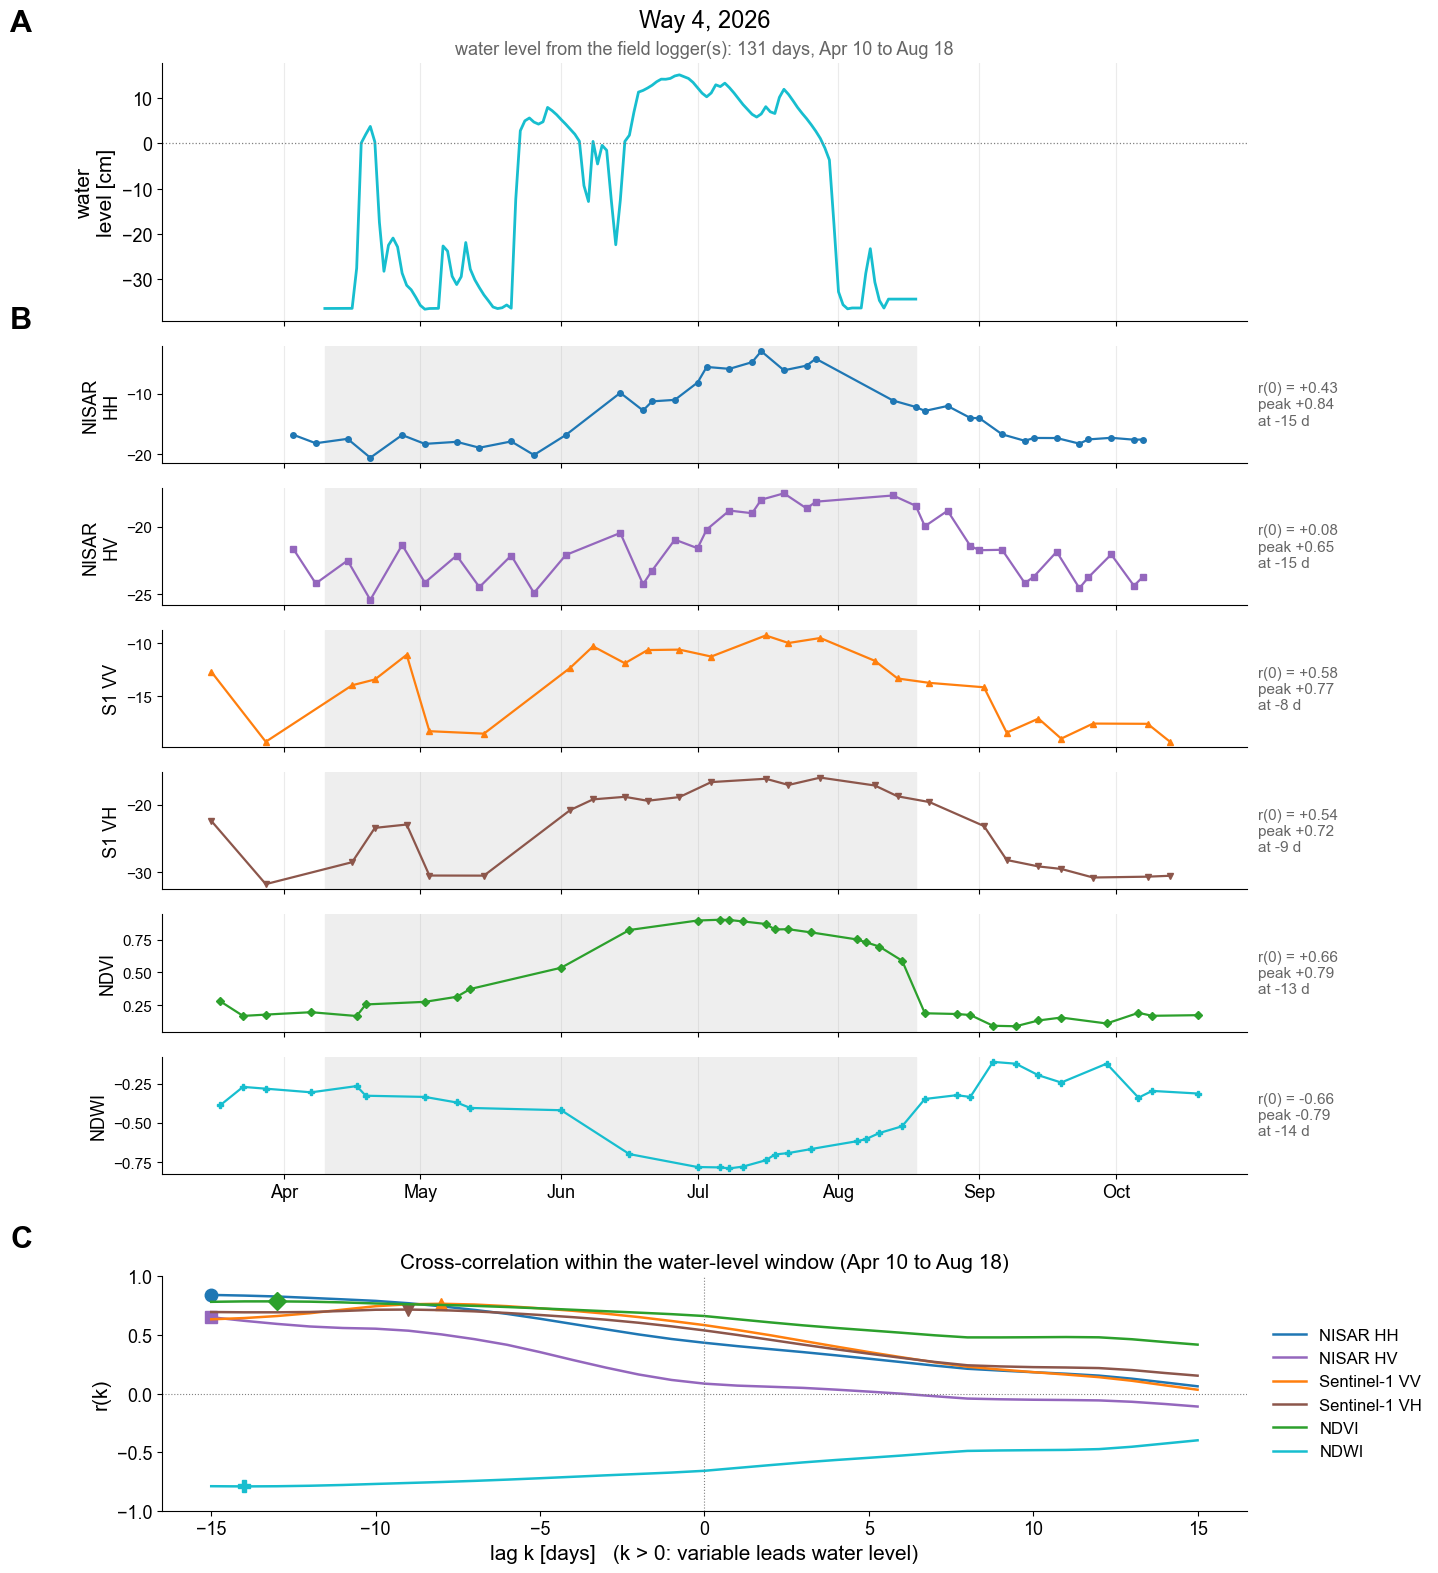

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


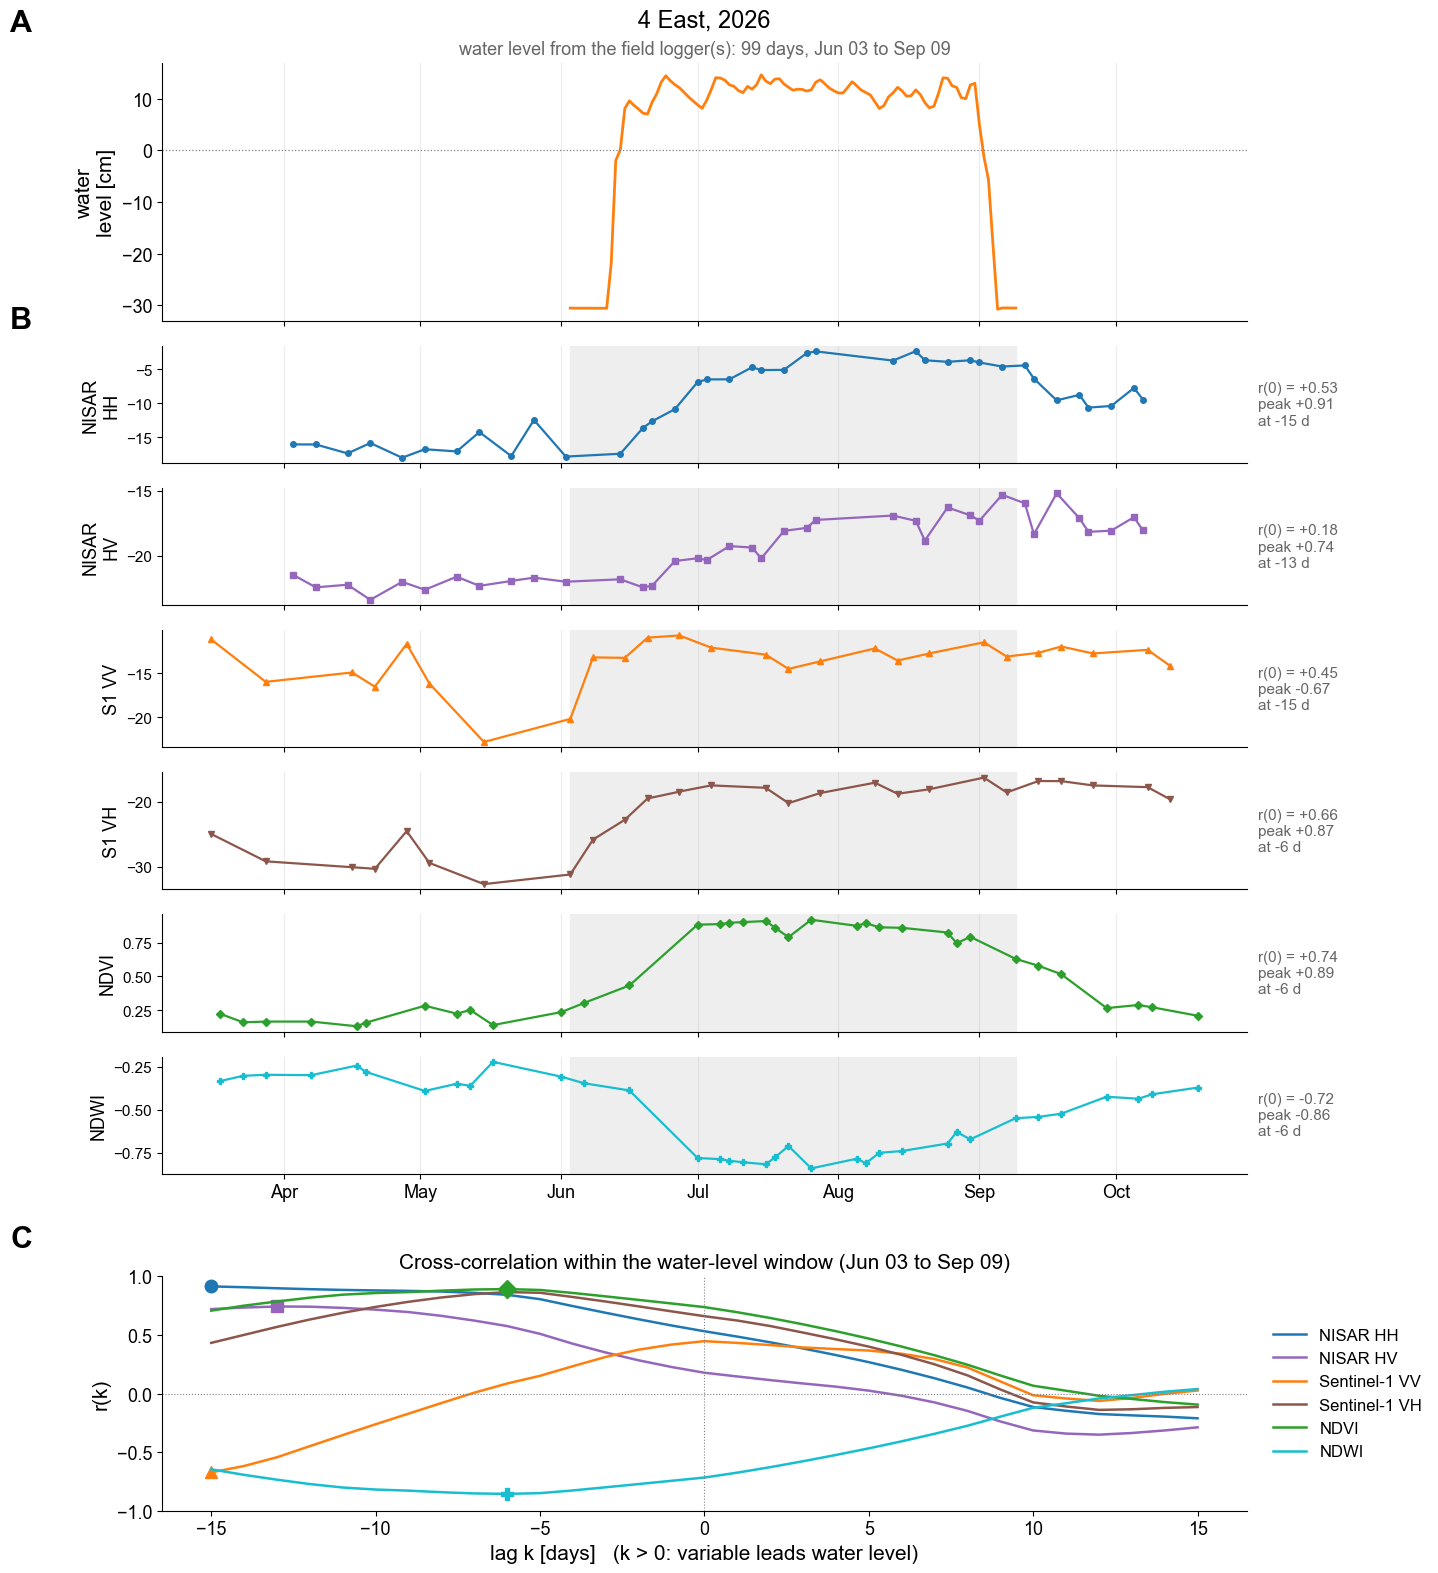

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


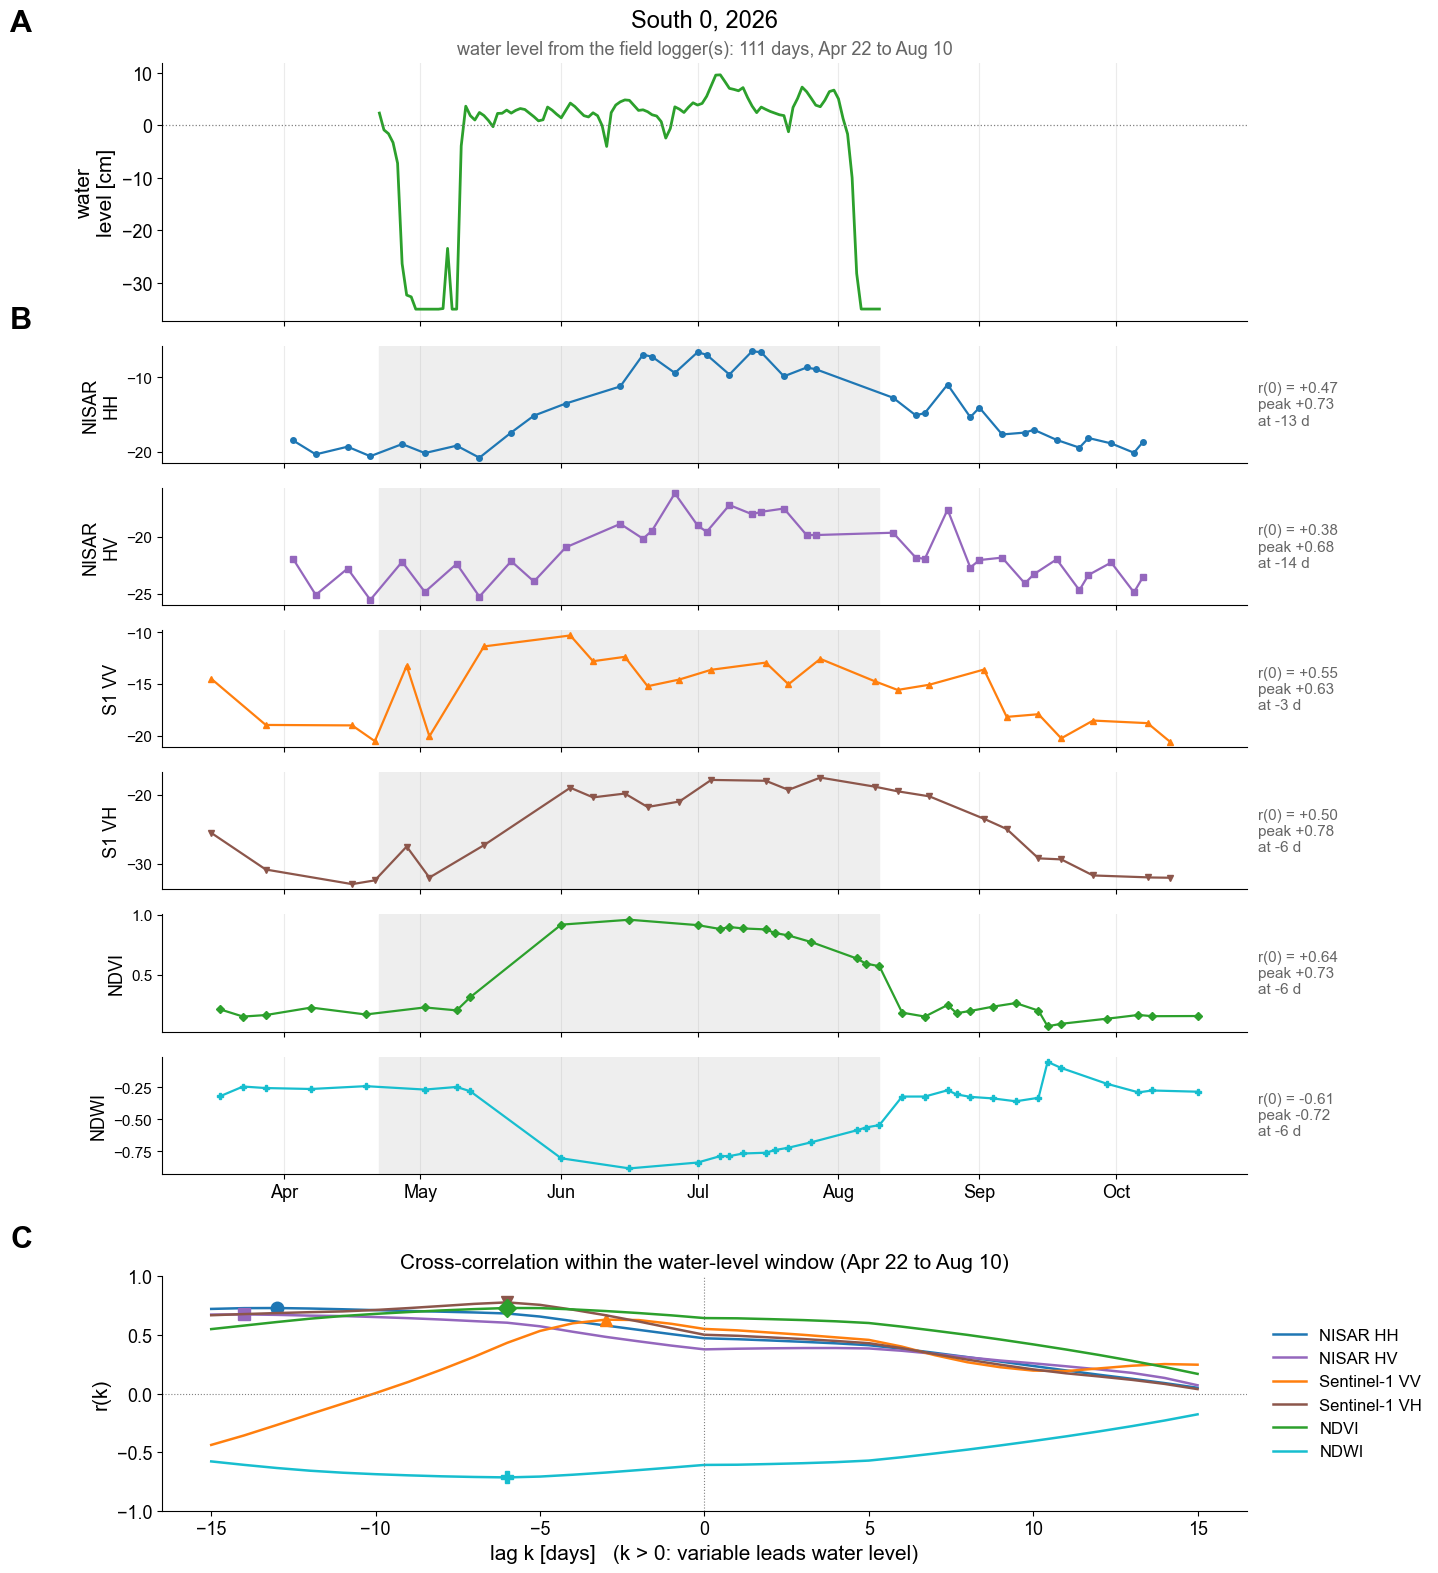

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


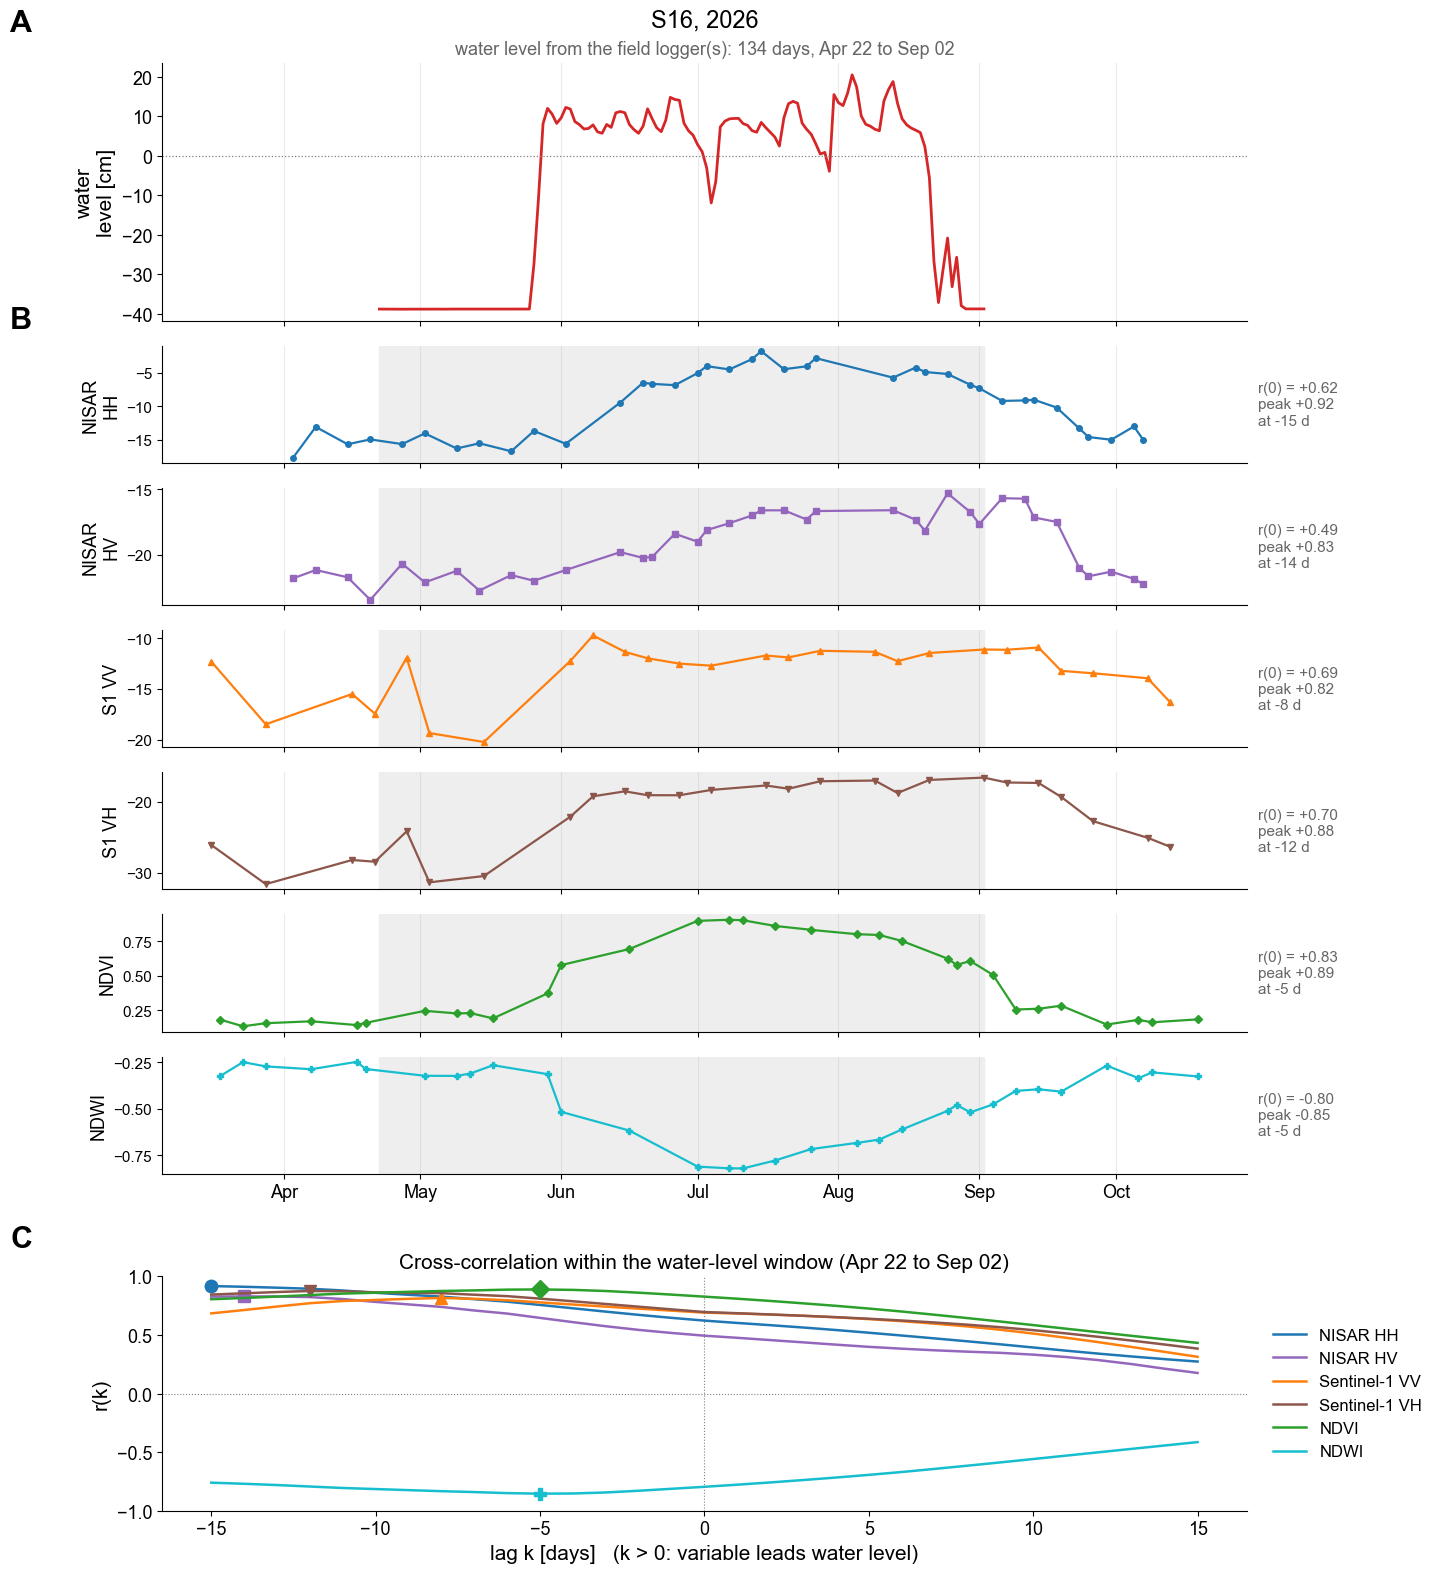

saved 5 figures to /Users/edliao/Documents/6_Projects/rice-methane-downscaling/outputs/eda_2026


In [6]:
def field_figure(field):
    g = d[d.field == field].sort_values("date")
    nb_ = len(SUMMARY_VARS)
    # Row heights: A is taller, then one strip per variable in panel B.
    fig = plt.figure(figsize=(14, 3.2 + 1.9 * nb_ + (4.2 if SHOW_CCF_PANEL else 0)))
    ratios = [2.2] + [1] * nb_ + ([0.45, 2.0] if SHOW_CCF_PANEL else [])   # spacer + panel C
    gs = fig.add_gridspec(len(ratios), 1, height_ratios=ratios, hspace=0.18)
    axes = [fig.add_subplot(gs[0])]
    for i in range(nb_):
        axes.append(fig.add_subplot(gs[1 + i], sharex=axes[0]))
    curves = []                                                       # for panel C
    # Water-level window for this field: first to last logger day. Cross-
    # correlation uses only days inside it, for BOTH series, so lagged pairs
    # never reach outside the period the loggers were running.
    lab_days = g.dropna(subset=["water_mean"]).date
    in_win = g.date.between(lab_days.min(), lab_days.max())

    # ---- A: water level ------------------------------------------------------
    ax = axes[0]
    ax.plot(g.date, g.water_mean, lw=2, color=FIELD_COLORS[field])
    ax.axhline(0, color="grey", lw=0.9, ls=":")
    ax.set_ylabel("water\nlevel [cm]")
    lab = g.dropna(subset=["water_mean"])
    ax.set_title(f"{field}, 2026", pad=26)
    subtitle(ax, f"water level from the field logger(s): {len(lab)} days, "
                 f"{lab.date.min():%b %d} to {lab.date.max():%b %d}")
    panel_letter(ax, "A")

    # ---- B: one strip per variable, connected lines --------------------------
    for i, (col, title, xlabel) in enumerate(SUMMARY_VARS):
        ax = axes[1 + i]
        color, marker = VAR_STYLE.get(col, ("grey", "o"))
        ax.plot(g.date, g[col], lw=1.6, color=color)                 # daily, connected
        gc = gap_col(col)
        obs = g[g[gc] == 0] if gc else g
        ax.plot(obs.date, obs[col], marker, ms=4, color=color, ls="none")   # real acquisitions
        ax.set_ylabel(title.replace("Sentinel-1 ", "S1 ").replace("NISAR ", "NISAR\n"),
                      fontsize=13)
        ax.tick_params(axis="y", labelsize=11)
        # Cross-correlation with water level, this field, on the daily series.
        x = g[col].where(g[gc] == 0) if (OBS_DAYS_ONLY and gc) else g[col]
        x = x.where(in_win)                                           # inside the window only
        ax.axvspan(lab_days.min(), lab_days.max(), color="#eeeeee", zorder=0)   # shade window
        r0, n0, rp, lp = ccf_summary(x.values, g.water_mean.values, MAX_LAG_DAYS)
        ax.text(1.01, 0.5, f"r(0) = {r0:+.2f}\npeak {rp:+.2f}\nat {lp:+d} d", transform=ax.transAxes,
                va="center", fontsize=11, color="#666666")
        lags, r, _ = ccf(x.values, g.water_mean.values, MAX_LAG_DAYS)
        curves.append((title, color, marker, lags, r, lp, rp))
    panel_letter(axes[1], "B")

    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    for ax in axes:
        ax.grid(axis="x", alpha=0.25)

    # ---- C: cross-correlation curves r(lag) ----------------------------------
    if SHOW_CCF_PANEL:
        ax = fig.add_subplot(gs[-1])
        for title, color, marker, lags, r, lp, rp in curves:
            ax.plot(lags, r, "-", lw=1.8, color=color, label=title)
            ax.plot([lp], [rp], marker, ms=9, color=color)            # peak
        ax.axhline(0, color="grey", lw=0.8, ls=":")
        ax.axvline(0, color="grey", lw=0.8, ls=":")
        ax.set_xlabel("lag k [days]   (k > 0: variable leads water level)")
        ax.set_title(f"Cross-correlation within the water-level window "
                     f"({lab_days.min():%b %d} to {lab_days.max():%b %d})", fontsize=15)
        ax.set_ylabel("r(k)")
        ax.set_ylim(-1, 1)
        ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=12)
        panel_letter(ax, "C")
    return fig


for f in fields:
    fig = field_figure(f)
    fig.savefig(OUT_DIR / f"summary_{f.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()
print(f"saved {len(fields)} figures to {OUT_DIR}")

## 7. Sentinel-2 B5 (red edge) per field

B5 (~705 nm) is the variable with the largest SHAP contribution in most of the F5 models. One row per field: the B5 reflectance (line = daily interpolated, dots = clear observations) and the field's water level (dashed, right axis); shaded = final drydown (after the last day with water ≥ 0 cm). Change `B5_COL` to plot another S2 variable.

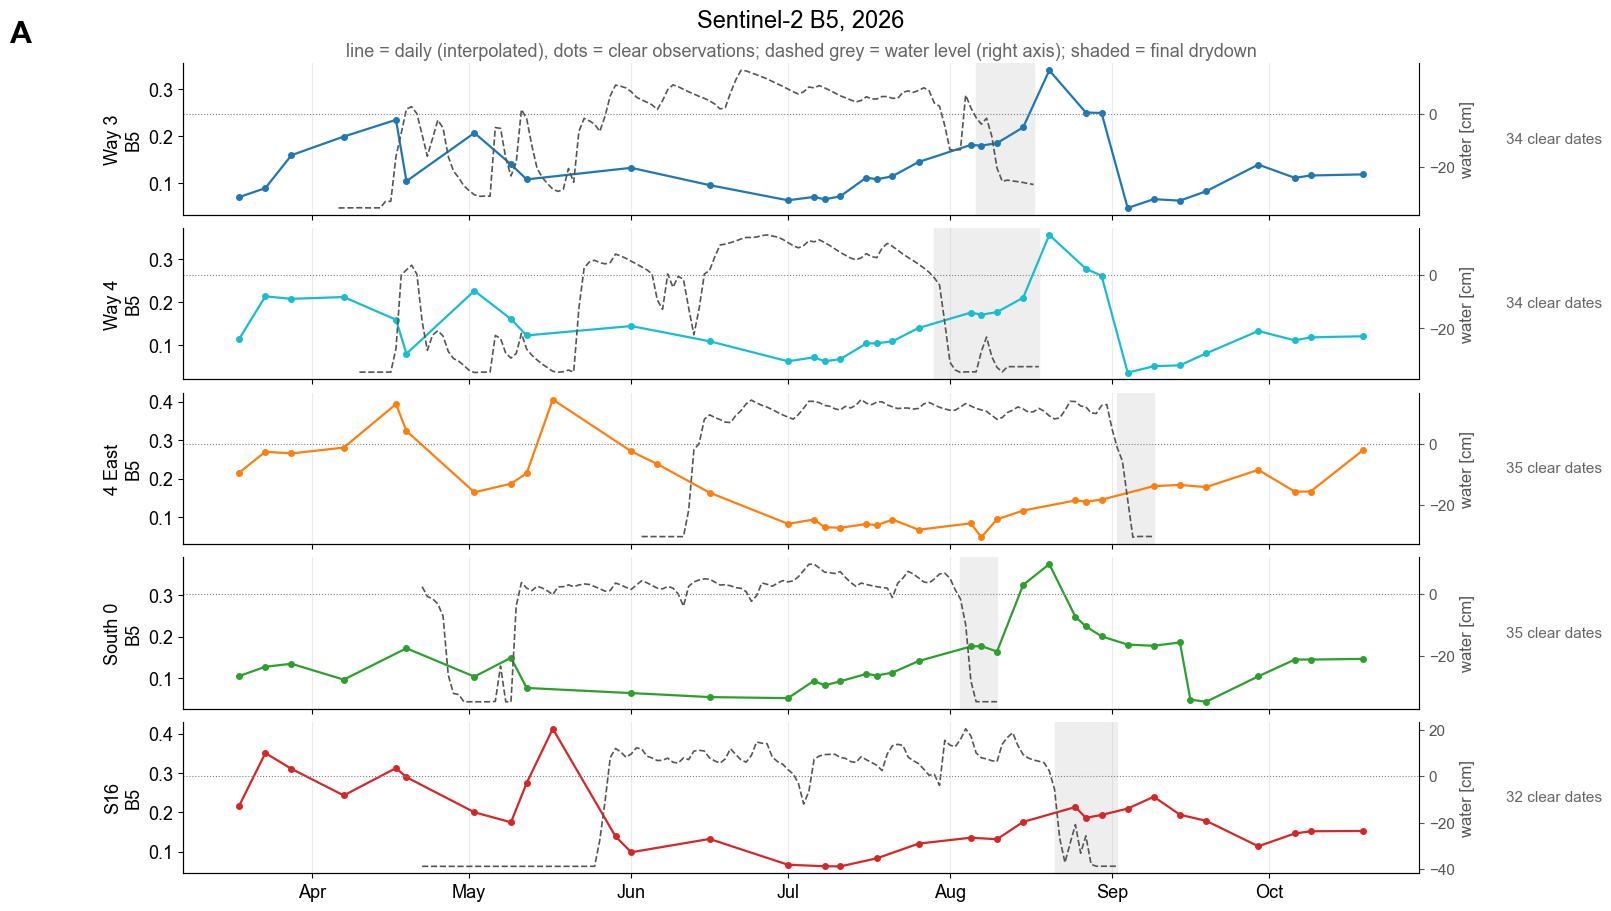

In [7]:
# Sentinel-2 band 5 (red edge, ~705 nm) per field, with the field's water level on the right axis.
# Line = daily (interpolated) value; dots = days with a real clear S2 observation (s2_gap_days == 0).
B5_COL    = "s2_B5"           # any S2 column works, e.g. "s2_B12" or "s2_ndvi"
B5_SCALE  = 1e4               # bands are stored as reflectance x 10000 (use 1 for ndvi / ndwi)
B5_SIZE, B5_DPI = (16, 9), 450   # 16:9 slide figure

last_wet = d[d.water_mean >= 0].groupby("field").date.max()      # start of the final drydown
fig, axes = plt.subplots(len(fields), 1, figsize=B5_SIZE, layout="constrained", sharex=True)
for ax, f in zip(np.atleast_1d(axes), fields):
    g = d[d.field == f].sort_values("date")
    obs = g[g.s2_gap_days == 0]
    col = FIELD_COLORS[f]
    ax.plot(g.date, g[B5_COL] / B5_SCALE, lw=1.6, color=col)                      # daily, interpolated
    ax.plot(obs.date, obs[B5_COL] / B5_SCALE, "o", ms=4, color=col)                # real observations
    ax.set_ylabel(f"{f}\n{B5_COL.replace('s2_', '')}", fontsize=13)
    ax2 = ax.twinx()                                                               # water level
    ax2.plot(g.date, g.water_mean, color="#555555", lw=1.2, ls="--")
    ax2.axhline(0, color="grey", lw=0.8, ls=":")
    ax2.set_ylabel("water [cm]", fontsize=12, color="#555555")
    ax2.tick_params(axis="y", labelsize=11, colors="#555555")
    ax2.spines["right"].set_visible(True)
    if f in last_wet.index:                                                        # shade the final drydown
        dd = g[(g.date > last_wet[f]) & g.water_mean.notna()]
        if len(dd):
            ax.axvspan(dd.date.min(), dd.date.max(), color="#eeeeee", zorder=0)
    ax.text(1.07, 0.5, f"{len(obs)} clear dates", transform=ax.transAxes, va="center", fontsize=11,
            color="#666666")
    ax.grid(axis="x", alpha=0.25)
top = np.atleast_1d(axes)[0]
top.set_title(f"Sentinel-2 {B5_COL.replace('s2_', '')}, 2026", pad=26)
subtitle(top, "line = daily (interpolated), dots = clear observations; dashed grey = water level (right axis); "
              "shaded = final drydown")
panel_letter(top, "A")
bottom = np.atleast_1d(axes)[-1]
bottom.xaxis.set_major_locator(mdates.MonthLocator())
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.savefig(OUT_DIR / f"timeseries_{B5_COL}.png", dpi=B5_DPI)
plt.show()